# Chronos-2 (as-is) — FinX model (Owen)

**Target:** `target_next_ret` = next-day S&P 500 return
**Input:** `ret_index` only (the index's own past), like SARIMA. The model gets no VIX, stocks or indicators.
**Validation:** the shared walk-forward harness (`walk_forward` in `src/finx_common.py`), same 3 folds as every FinX model.

| Fold | Train | Test |
|---|---|---|
| 1 | 2021-01-04 to 2023 | 2024 |
| 2 | 2021-01-04 to 2024 | 2025 |
| 3 | 2021-01-04 to 2025 | 2026 to 21 Sep |

**What the model is:** Chronos-2 is Amazon's successor to Chronos-Bolt (Oct 2025, 120M parameters). Like Bolt it is pretrained on
public and synthetic series (not stock returns specifically) and is used here **as-is**: nothing is trained on our data.
It cuts the history into 16-day patches, scales it itself, and outputs 21 quantiles (1% to 99%) of the next value in one
pass, without sampling, so the same input always gives the same forecast. Chronos-2 can also read extra series, but here
it gets `ret_index` only, exactly like Chronos-Bolt and SARIMA, so the two Chronos models are compared on equal inputs.

**Settings (fixed in advance, no tuning on test years):** `amazon/chronos-2` (120M parameters), CPU, float32, seed 42. For test day t the
input is every `ret_index` value from 2021-01-04 up to and including day t (at most 1,435 values, below Chronos-2's
8,192 limit, so nothing is cut). The point forecast is the median (0.5 quantile). No scaling and no validation
slice are needed because nothing is trained. `fit` only loads the weights, so "train time" is load time.
The 5-day window rule is for the lag-feature models; a 5-value history would be far too short for Chronos.
Code: `models/chronos2_model.py`.

**Limitation:** Chronos-2 was released in Oct 2025, so its pretraining data may overlap the 2024 and 2025 test years.
It was not trained on stock returns specifically, so the risk is small, but it is a possible look-ahead.

**Outputs:** `outputs/preds_chronos2.csv` and `outputs/timing_chronos2.json` (written by the harness);
`outputs/chronos2/chronos2_folds.csv`, `chronos2_quantiles.csv`, `chronos2_scores.csv`, `chronos2_vs_models.csv` and `fig_chronos2_band_<year>.png`.

## 1. Setup
Needs `pip install chronos-forecasting` (2.x; brings PyTorch). The weights (about 480 MB) download once on first use.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "src"), str(ROOT / "models")]
import config as C
import chronos2_model as M   # fit / predict / predict_quantiles / NAME
from finx_common import FOLDS, fold_split, load_master, score, walk_forward

warnings.filterwarnings("ignore")
%matplotlib inline
pd.set_option("display.width", 160)
OUT = C.OUT_DIR / "chronos2"
OUT.mkdir(parents=True, exist_ok=True)

## 2. Load the frozen master

In [2]:
master = load_master()                 # checksum and row count are checked on load
ret = master["ret_index"]
print(f"{len(master)} trading days: {master.index.min().date()} to {master.index.max().date()}")
assert (master[C.TARGET].iloc[:-1].values == ret.shift(-1).iloc[:-1].values).all()
assert len(master) <= M.CONTEXT
print(f"Check passed: target on day t = ret_index on day t+1, so the forecast for day t+1 uses ret_index up to day t. "
      f"Longest history ({len(master)} days) fits in Chronos-2's {M.CONTEXT}-value context.")

1435 trading days: 2021-01-04 to 2026-09-21
Check passed: target on day t = ret_index on day t+1, so the forecast for day t+1 uses ret_index up to day t. Longest history (1435 days) fits in Chronos-2's 8192-value context.


## 3. Walk-forward run (shared harness)
The first call downloads the weights, which would make fold 2024's load time look slow. The warm-up line loads them once
before the timed run, so every fold's "train time" is the same thing: loading cached weights from disk.
`walk_forward` then loads once per fold, predicts every test day, times the latency of one next-day prediction, and writes
`preds_chronos2.csv` and `timing_chronos2.json`. The wrapper only keeps each fold's model so section 4 can
read the quantiles without loading again.

In [3]:
M.fit(master.iloc[:5])                  # warm-up: download / cache the weights (not timed)

fitted = []

def fit_and_keep(train):
    m = M.fit(train)
    fitted.append(m)
    return m

P, timing = walk_forward(fit_and_keep, M.predict, M.NAME, df=master)

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 2697.58it/s]

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading weights:  15%|█▌        | 26/170 [00:00<00:00, 151.35it/s]

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 634.66it/s]

...

Loading weights:  10%|█         | 17/170 [00:00<00:00, 169.08it/s]

Loading weights:  20%|██        | 34/170 [00:00<00:01, 128.75it/s]

Loading weights:  74%|███████▍  | 126/170 [00:00<00:00, 434.88it/s]

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 470.13it/s]

[chronos2] fold 2026: train 1255 days, test 180 days, train 2.0s, 149.168 ms for one prediction


In [4]:
# Checks that the run matches the spec
n_test = sum(len(fold_split(master, f)[1]) for f in FOLDS)
assert len(fitted) == 3
assert len(P) == n_test, (len(P), n_test)
assert P["pred"].notna().all()
assert all(str(m.model.device) == M.DEVICE for m in fitted)

# No peeking: a forecast made with data only up to day t equals the one from the full run
d = P.index[300]
alone = M.predict(fitted[1], master.loc[:d], pd.DatetimeIndex([d])).iloc[0]
assert np.isclose(alone, P.loc[d, "pred"], atol=1e-6), (alone, P.loc[d, "pred"])
print(f"{len(P)} pooled predictions over {len(fitted)} folds; forecast for {d.date()} is the same with or without later data.")

682 pooled predictions over 3 folds; forecast for 2025-03-14 is the same with or without later data.


## 4. Context per fold, and the forecast band
Chronos-2 gives a range, not just one number. Below, the 10% and 90% quantiles form an 80% band around the median.
If the band were well calibrated, about 80% of actual returns would fall inside it. "Band vs VIX" is the correlation
between the band's width and that day's VIX: a positive value means the model widens its range on stressed days, even
though it never sees VIX.

In [5]:
Q = pd.concat([M.predict_quantiles(m, master, fold_split(master, f)[1].index) for f, m in zip(FOLDS, fitted)])
Q = Q.join(P[["fold", "actual", "VIX"]])
assert np.allclose(Q["q50"], P["pred"])
Q.to_csv(OUT / "chronos2_quantiles.csv")

rows = []
for fold, m in zip(FOLDS, fitted):
    train, test = fold_split(master, fold)
    q = Q[Q["fold"].astype(str) == fold[0]]
    width = q["q90"] - q["q10"]
    rows.append({"test_year": fold[0], "train_days": len(train), "test_days": len(test),
                 "context_first_day": len(train), "context_last_day": len(train) + len(test) - 1,
                 "load_s": round(timing["train_s"][fold[0]], 2),
                 "median forecast min (%)": round(q["q50"].min() * 100, 4),
                 "median forecast max (%)": round(q["q50"].max() * 100, 4),
                 "inside 10-90% band (%)": round(100 * ((q["actual"] >= q["q10"]) & (q["actual"] <= q["q90"])).mean(), 1),
                 "band width mean (%)": round(width.mean() * 100, 3),
                 "band vs VIX (corr)": round(width.corr(q["VIX"]), 3)})
folds = pd.DataFrame(rows)
folds.to_csv(OUT / "chronos2_folds.csv", index=False)
folds

,test_year,train_days,test_days,context_first_day,context_last_day,load_s,median forecast min (%),median forecast max (%),inside 10-90% band (%),band width mean (%),band vs VIX (corr)
0,2024,753,252,753,1004,1.76,0.0177,0.1511,79.4,2.013,0.763
1,2025,1005,250,1005,1254,1.82,-0.0473,0.1601,82.4,2.305,0.780
2,2026,1255,180,1255,1434,2.02,0.0123,0.1448,80.6,2.067,0.534


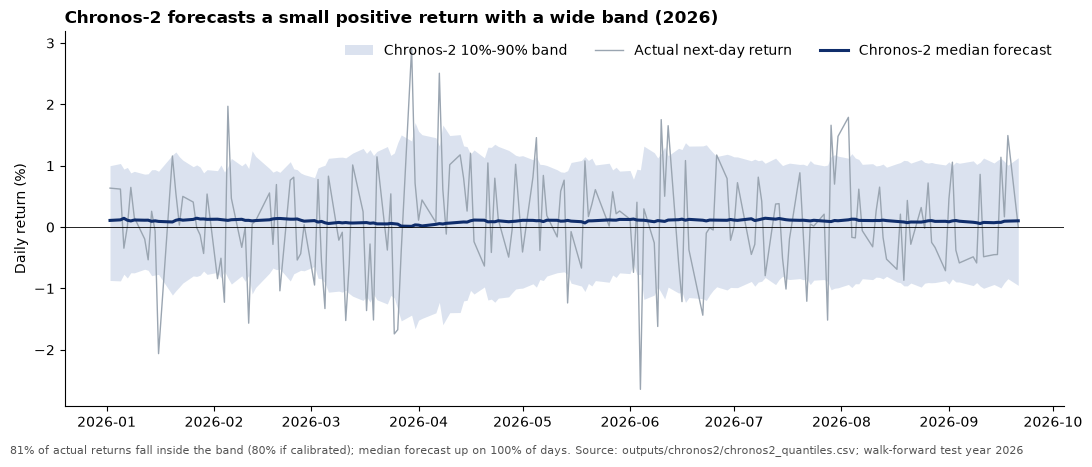

In [6]:
yr = FOLDS[-1][0]
q = Q[Q["fold"].astype(str) == yr]
inside = 100 * ((q["actual"] >= q["q10"]) & (q["actual"] <= q["q90"])).mean()
up = 100 * (q["q50"] > 0).mean()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(q.index, q["q10"] * 100, q["q90"] * 100, color="#5b7fb8", alpha=0.22, lw=0, label="Chronos-2 10%-90% band")
ax.plot(q.index, q["actual"] * 100, color="#9aa5b1", lw=1, label="Actual next-day return")
ax.plot(q.index, q["q50"] * 100, color="#0f2d6b", lw=2.2, label="Chronos-2 median forecast")
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("Daily return (%)")
ax.set_title(f"Chronos-2 forecasts a small {'positive' if up >= 50 else 'negative'} return with a wide band ({yr})",
             fontsize=12, fontweight="bold", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right", ncol=3)
fig.text(0.01, -0.02, f"{inside:.0f}% of actual returns fall inside the band (80% if calibrated); median forecast up on {up:.0f}% of days. "
         f"Source: outputs/chronos2/chronos2_quantiles.csv; walk-forward test year {yr}", fontsize=8, color="#555")
fig.tight_layout()
fig.savefig(OUT / f"fig_chronos2_band_{yr}.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Scores
All test days pooled (not averaged per fold), then each fold. Naive = always predict 0, so naive RMSE = sqrt(mean(actual^2)).
Skill vs naive = 1 − RMSE(model) ÷ RMSE(naive). "Always up (%)" is the share of days the market rose, the direction
benchmark. "Forecast up (%)" is the share of days Chronos-2 predicted a positive return: at 100%, its Direction equals
"always up" by construction.

In [7]:
def row(g, label):
    a = g["actual"]
    s = score(a, g["pred"], float(np.sqrt((a ** 2).mean())))
    up = 100 * (a[a != 0] > 0).mean()
    return {"test days": label, "n": len(g), "RMSE (%)": s["RMSE"] * 100, "MAE (%)": s["MAE"] * 100,
            "Direction (%)": s["Direction %"], "Always up (%)": up,
            "Skill vs naive (%)": s["Skill vs naive"] * 100, "Forecast up (%)": 100 * (g["pred"] > 0).mean()}

scores = pd.DataFrame([row(P, "pooled")] + [row(g, str(f)) for f, g in P.groupby("fold")]).round(3)
scores.to_csv(OUT / "chronos2_scores.csv", index=False)
t = {k: float(np.mean(list(v.values()))) for k, v in timing.items() if k != "hardware"}
print(f"Load time per fold: {t['train_s']:.2f} s   Inference per day: {t['latency_ms_per_day']:.2f} ms   "
      f"Hardware: {timing['hardware']}")
scores

Load time per fold: 1.87 s   Inference per day: 138.68 ms   Hardware: {'cpu': 'AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD', 'cores': 16, 'gpu': 'NVIDIA GeForce GTX 1650'}


,test days,n,RMSE (%),MAE (%),Direction (%),Always up (%),Skill vs naive (%),Forecast up (%)
0,pooled,682,0.966,0.655,56.158,56.012,-0.016,99.853
1,2024,252,0.796,0.588,56.746,56.746,0.398,100.000
2,2025,250,1.183,0.728,58.400,58.000,-0.182,99.600
3,2026,180,0.841,0.648,52.222,52.222,-0.085,100.000


## 6. Chronos-2 next to the models already run
Same pooled scoring, read from each model's `outputs/preds_<name>.csv`. Timings come from each model's own
`timing_<name>.json`, so they are only comparable when the hardware column matches.

In [8]:
LABELS = {"naive": "Naive (return = 0)", "arima": "ARIMA", "sarima": "SARIMA", "xgboost": "XGBoost",
          "dnn": "DNN", "lstm": "LSTM", "chronos_asis": "Chronos-Bolt (as-is)", "chronos2": "Chronos-2 (as-is)"}
rows = []
for k, lab in LABELS.items():
    f = C.OUT_DIR / f"preds_{k}.csv"
    if not f.exists():
        continue
    g = pd.read_csv(f, index_col=0, parse_dates=True)
    tj = json.loads((C.OUT_DIR / f"timing_{k}.json").read_text())
    r = row(g, lab)
    r.update({"Train / load per fold (s)": np.mean(list(tj["train_s"].values())),
              "Inference per day (ms)": np.mean(list(tj["latency_ms_per_day"].values())),
              "Hardware": f"{tj['hardware']['cpu']}, {tj['hardware']['cores']} cores, GPU {tj['hardware']['gpu']}"})
    rows.append(r)
compare = pd.DataFrame(rows).rename(columns={"test days": "model"}).drop(columns=["n", "Always up (%)"]).round(3)
compare.loc[compare["model"] == LABELS["naive"], ["Direction (%)", "Forecast up (%)"]] = np.nan   # 0 has no direction
compare.to_csv(OUT / "chronos2_vs_models.csv", index=False)
compare

,model,RMSE (%),MAE (%),Direction (%),Skill vs naive (%),Forecast up (%),Train / load per fold (s),Inference per day (ms),Hardware
0,Naive (return = 0),0.966,0.658,NaN,0.000,NaN,0.000,0.042,"arm, 11 cores, GPU none"
1,ARIMA,0.964,0.655,54.106,0.228,96.041,1.463,2.533,"arm, 11 cores, GPU none"
2,SARIMA,0.964,0.654,56.012,0.260,100.000,10.864,5.538,"arm, 12 cores, GPU none"
3,XGBoost,0.962,0.655,54.985,0.387,94.868,0.092,12.840,"arm, 11 cores, GPU none"
4,DNN,1.024,0.731,52.346,-5.959,57.331,7.148,33.277,"AMD64 Family 23 Model 96 Stepping 1, Authentic..."
5,Chronos-Bolt (as-is),0.968,0.656,55.425,-0.187,92.375,2.246,205.176,"AMD64 Family 25 Model 68 Stepping 1, Authentic..."
6,Chronos-2 (as-is),0.966,0.655,56.158,-0.016,99.853,1.868,138.675,"AMD64 Family 25 Model 68 Stepping 1, Authentic..."


## 7. Notes for the group chat
Three lines, each quoting a number from the tables above. The cell below fills the numbers from the computed results;
the verdict words (better/worse, above/below) are also computed. Replace each `[reason: ...]` with a short explanation
only after looking at the outputs (for example the band chart, the fold table or the forecast-up share).
Do not tune on the test years to change these numbers.

In [9]:
s = scores.iloc[0]
f = scores.iloc[1:].set_index("test days")
c = compare.set_index("model")
better = lambda x: "better" if x > 0 else "worse"
best_fold, worst_fold = f["Skill vs naive (%)"].idxmax(), f["Skill vs naive (%)"].idxmin()
others = c.drop(index=[LABELS[M.NAME], "Naive (return = 0)"], errors="ignore")
best_other = others["Skill vs naive (%)"].idxmax()
twin = "Chronos-Bolt (as-is)"
vs_twin = (f"; {twin} scores {c.loc[twin, 'Skill vs naive (%)']:+.2f}% on the same input" if twin in c.index else "")
print(f"1. RMSE: Chronos-2 {s['RMSE (%)']:.3f}% vs naive {100 * np.sqrt((P['actual'] ** 2).mean()):.3f}% "
      f"(skill {s['Skill vs naive (%)']:+.2f}%), so {better(s['Skill vs naive (%)'])} than naive on all {int(s['n'])} days; "
      f"best other model is {best_other} at {others.loc[best_other, 'Skill vs naive (%)']:+.2f}%{vs_twin}. [reason: ...]")
print(f"2. Direction: {s['Direction (%)']:.1f}% vs always-up {s['Always up (%)']:.1f}%, "
      f"{'above' if s['Direction (%)'] > s['Always up (%)'] else 'not above'} the benchmark; "
      f"Chronos-2 forecast up on {s['Forecast up (%)']:.1f}% of days. [reason: ...]")
print(f"3. By fold: skill vs naive is best in {best_fold} ({f.loc[best_fold, 'Skill vs naive (%)']:+.2f}%) "
      f"and worst in {worst_fold} ({f.loc[worst_fold, 'Skill vs naive (%)']:+.2f}%); "
      f"actual returns inside the 80% band per fold: {', '.join(f'{x:.0f}%' for x in folds['inside 10-90% band (%)'])}. [reason: ...]")

1. RMSE: Chronos-2 0.966% vs naive 0.966% (skill -0.02%), so worse than naive on all 682 days; best other model is XGBoost at +0.39%; Chronos-Bolt (as-is) scores -0.19% on the same input. [reason: ...]
2. Direction: 56.2% vs always-up 56.0%, above the benchmark; Chronos-2 forecast up on 99.9% of days. [reason: ...]
3. By fold: skill vs naive is best in 2024 (+0.40%) and worst in 2025 (-0.18%); actual returns inside the 80% band per fold: 79%, 82%, 81%. [reason: ...]


In [10]:
s = scores.iloc[0]
print(f"Chronos-2 (as-is) (all {int(s['n'])} test days): RMSE {s['RMSE (%)']:.3f}%  MAE {s['MAE (%)']:.3f}%  "
      f"Direction {s['Direction (%)']:.1f}%  Skill vs naive {s['Skill vs naive (%)']:+.2f}%")
print(f"Load {t['train_s']:.2f} s per fold  |  Inference {t['latency_ms_per_day']:.2f} ms per day  |  "
      f"Hardware: {timing['hardware']['cpu']}, {timing['hardware']['cores']} cores, GPU {timing['hardware']['gpu']} (model runs on {M.DEVICE})")

Chronos-2 (as-is) (all 682 test days): RMSE 0.966%  MAE 0.655%  Direction 56.2%  Skill vs naive -0.02%
Load 1.87 s per fold  |  Inference 138.68 ms per day  |  Hardware: AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD, 16 cores, GPU NVIDIA GeForce GTX 1650 (model runs on cpu)
